In [1]:
import numpy as np
import matplotlib.pyplot as plt
from typing import Union, Callable, Optional, Literal
from scipy import sparse as spsp
from numpy.typing import ArrayLike

Next Steps:
- Plot J - Done
- Optimise - Done
    - Look at LU.
    - Ask to look at Yue's code. How is hers so fast? Maybe it is just because she used a big time step? Then mine compares.
- Make specialised code for scheme B - Done
    - Result: ~2x speed up. I should use this for 2D.
- Do explicit comparison. Write it up.
- Look at 2D
    - I don't remember how to do this

In [2]:
class SolverMixin:
    def newton_vec(self,
        xk: Union[float, int],
        F: Callable,
        J: Callable,
        damping: Union[float, int] = 1,
        tol: float = 1e-14,
        max_iter: int = 100,
        return_iter_count: bool = False
        ) -> float:
        r"""Use the Newton-Raphson algorithm to find a root of a given function from a starting point.

        Args
        ----
            xl: float or int
                point at which to start the algorithm
            f: callable
                function to find a roots of
            df: callable
                derivative of arg `f`
            damping: float or int
                scaling applied to the search distance
            tol: float
                desired tolerance of the root (how close to zero it is)
            max_iter: int
                maximum number of iterations to search for a root
            return_iter_count: bool
                indicates if the iteration count should be returned
        """
        k = 0
        while (abs(F(xk)).sum() > tol) and (k < max_iter):
            xk = xk + damping * spsp.linalg.spsolve(J(xk), -F(xk))
            k += 1
        
        if return_iter_count:
            return xk, k
        return xk

class CahnHilliard1D(SolverMixin):
    def __init__(self,
                a: float,
                b: float,
                N: int,
                init_cond: Callable,
                phi: Callable,
                phi_p: Callable,
                phi_pp: Callable,
                boundary_type: Literal['Neumann', 'Dirichlet'] = 'Neumann',
                eps: float = 0.01,
                dt: Optional[float] = None
                ):
        self.a = a
        self.b = b
        self.N = N
        self.dx = (b-a)/(N-1)
        self.init_cond = init_cond
        self.phi = phi
        self.phi_p = phi_p
        self.phi_pp = phi_pp
        self.boundary_type = boundary_type
        self.eps = eps

        if dt == None:
            self.dt = self.dx**4*100
        else:
            self.dt = dt
        self.mu = self.dt / (self.dx**2)

        self.mesh = np.linspace(a, b, N)

        C0 = init_cond(self.mesh)
        W0 = np.zeros(C0.shape)

        self.Un = np.concat([C0, W0])
        self.A = self.construct_A()
        self.mat_base = self._make_mat_base()

        self._make_J_mat()
        self.J = self.compute_J()

        self.M = self.compute_M()

    def construct_A(self):
        A = spsp.diags([np.ones(self.N-1), -2*np.ones(self.N), np.ones(self.N-1)], [-1, 0, 1])

        if self.boundary_type == 'Neumann':
            A += spsp.csc_matrix(([1, 1], [(0, self.N-1), (1, self.N-2)]), [self.N, self.N])
        elif self.boundary_type == 'Dirichlet':
            raise NotImplementedError("Dirichlet B.C.s not yet implemented")
        return A

    def _make_mat_base(self):
        I = spsp.eye(self.N)
        return spsp.block_array([[I, -self.A*self.mu], [self.eps * self.A/(self.dx**2), I]])
    
    def step(self):
        F = lambda x: self.mat_base@x - np.concat([self.Un[:self.N], self.phi_p(x[:self.N])/self.eps])
        J = lambda y: self.mat_base - spsp.diags(self.phi_pp(y[:self.N]), -self.N)/self.eps
        self.Un = self.newton_vec(self.Un, F, J, tol=1e-12, max_iter=20)

    def _make_J_mat(self):

        dneg1 = -np.ones(self.N - 1)
        dneg1[-1] = -2

        d0 = np.zeros(self.N)
        d0[0] = -2
        d0[-1] = 2

        dpos1 = np.ones(self.N - 1)
        dpos1[0] = 2

        self._J_mat = spsp.diags([dneg1, d0, dpos1], [-1, 0, 1]) / (2 * self.dx)
    
    def compute_J(self):
        c = self.Un[:self.N]
        term_1 = 1/self.eps * self.phi(c)
        term_2 = self.eps * (self._J_mat@c)**2 / 2

        return (term_1 + term_2).sum()
    
    def compute_M(self):
        c = self.Un[:self.N]
        return self.dx * (c[1:] + c[:-1]).sum() / 2

In [ ]:
class SemiImplicitCH(CahnHilliard1D):
    def step(self):
        F = lambda x: self.mat_base@x - np.concat([self.Un[:self.N], self.phi_p(x[:self.N], self.Un[:self.N])/self.eps])
        J = lambda y: self.mat_base - spsp.diags(self.phi_pp(y[:self.N], self.Un[:self.N]), -self.N)/self.eps
        self.Un = self.newton_vec(self.Un, F, J, tol=1e-12, max_iter=20)

class CHSchemeB(CahnHilliard1D):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.compute_lu()

    def step(self):
        F = lambda x: self.mat_base@x - np.concat([self.Un[:self.N], self.phi_p(x[:self.N], self.Un[:self.N])/self.eps])
        self.Un = self.lu_newton(self.Un, F, tol=1e-12, max_iter=20)

    def compute_lu(self):
        J = self.mat_base - spsp.diags(2*np.ones(self.N), -self.N)/self.eps
        self.lu = spsp.linalg.splu(J.tocsc())

    def lu_newton(self,
        xk: Union[float, int],
        F: Callable,
        tol: float = 1e-13,
        max_iter: int = 100,
        ) -> float:
        k = 0
        while (abs(F(xk)).sum() > tol) and (k < max_iter):
            xk = xk + self.lu.solve(-F(xk))
            k += 1
        return xk
    

class CHSchemeB(CahnHilliard1D):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.compute_lu()

    def step(self):
        Cn = self.Un[:self.N]
        rhs2 = (Cn**3 - 3*Cn)/self.eps
        self.Un = self.lu.solve(np.hstack([Cn, rhs2]))

    def compute_lu(self):
        A = self.mat_base - spsp.diags(2*np.ones(self.N) / self.eps, -self.N)
        self.lu = spsp.linalg.splu(A.tocsc())

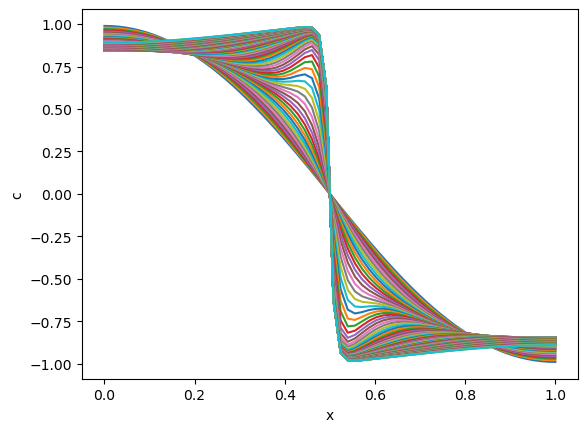

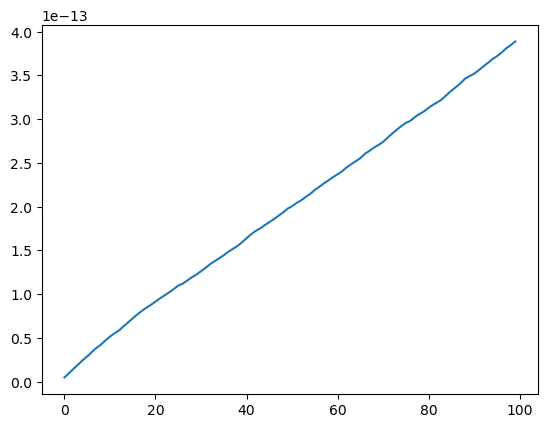

In [18]:
N = 64
n_steps = 100
sample_every = 1

phi = lambda x: (1-x**2)**2/4
phi_p = lambda x, y: 2*x+y**3-3*y
phi_pp = None
solver = CHSchemeB(0, 1, N, lambda x: np.cos(np.pi * x), phi, phi_p, phi_pp)
vals = []
J_vals = []
M_vals = []
for i in range(n_steps):
    solver.step()
    if i % sample_every == 0:
        vals.append(solver.Un[:N])
    J_vals.append(solver.compute_J())
    M_vals.append(solver.compute_M())

plt.plot(solver.mesh, list(zip(*vals)))
plt.ylabel('c')
plt.xlabel('x')

plt.show()
plt.plot(M_vals)

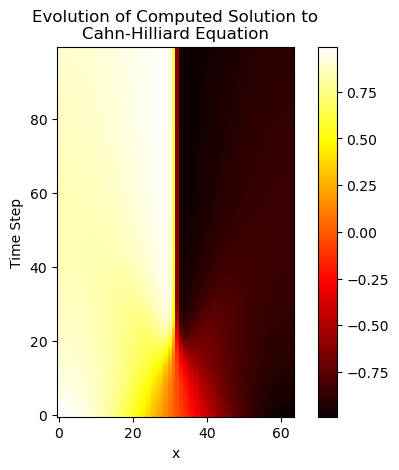

In [5]:
plt.imshow(np.array(vals), cmap='hot', interpolation='nearest', origin='lower')
# plt.xticks([0, 25, 50, 75, 99], [0, 0.25, 0.5, 0.75, 1])
# plt.clim([-1, 1])
plt.colorbar()
plt.ylabel('Time Step')
plt.xlabel('x')
plt.title('Evolution of Computed Solution to\nCahn-Hilliard Equation')
plt.show()

### Fully Implicit Scheme

Text(0.5, 0, 'x')

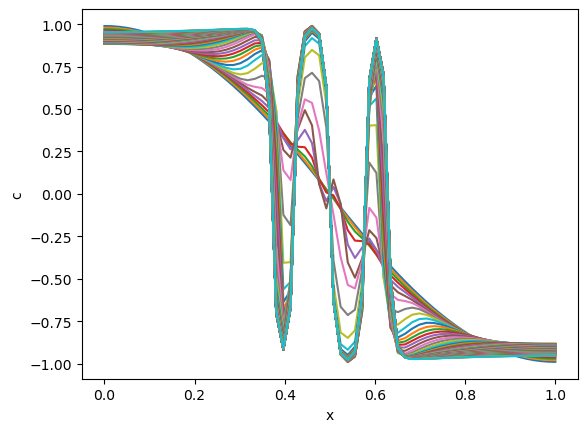

In [6]:
phi = lambda x: (1-x**2)**2/4
phi_p = lambda x: -x+x**3
phi_pp = lambda x: -1+3*x**2
solver = CahnHilliard1D(0, 1, N, lambda x: np.cos(np.pi * x), phi, phi_p, phi_pp)
vals = []
for i in range(n_steps):
    solver.step()
    if i % int(sample_every) == 0:
        vals.append(solver.Un[:N])

plt.plot(solver.mesh, list(zip(*vals)))
plt.ylabel('c')
plt.xlabel('x')

### Scheme A

Text(0.5, 0, 'x')

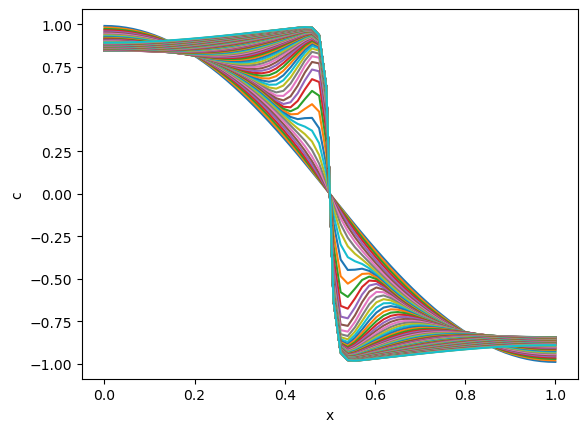

In [7]:
phi_p = lambda x, y: -y+x**3
phi_pp = lambda x, y: 3*x**2
solver = SemiImplicitCH(0, 1, N, lambda x: np.cos(np.pi * x), phi, phi_p, phi_pp)
vals = []
for i in range(n_steps):
    solver.step()
    if i % int(sample_every) == 0:
        vals.append(solver.Un[:N])

plt.plot(solver.mesh, list(zip(*vals)))
plt.ylabel('c')
plt.xlabel('x')

### Scheme B

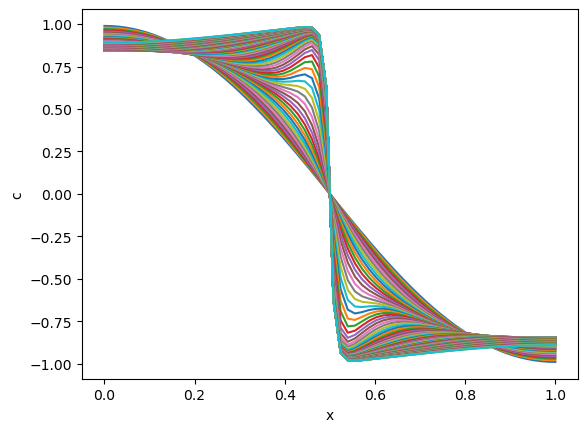

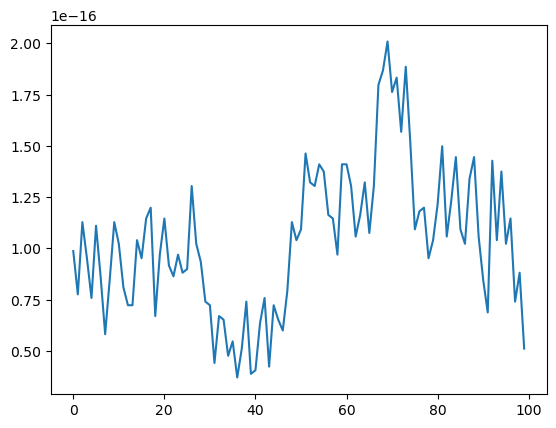

In [8]:
phi_p = lambda x, y: 2*x+y**3-3*y
phi_pp = lambda x, y: 2 * np.ones(len(x))
solver = SemiImplicitCH(0, 1, N, lambda x: np.cos(np.pi * x), phi, phi_p, phi_pp)
vals = []
Ms = []
for i in range(n_steps):
    solver.step()
    if i % int(sample_every) == 0:
        vals.append(solver.Un[:N])
        Ms.append(solver.compute_M())

plt.plot(solver.mesh, list(zip(*vals)))
plt.ylabel('c')
plt.xlabel('x')
plt.show()
plt.plot(Ms)

### Scheme C

Text(0.5, 0, 'x')

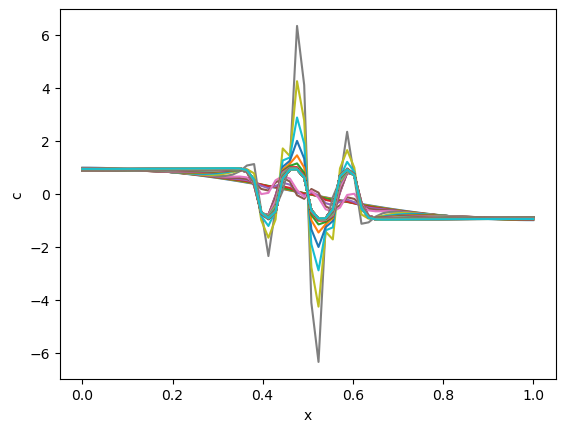

In [9]:
phi_p = lambda x, y: 3*x*y**2 - x - 2 * y**3
phi_pp = lambda x, y: 3*y**2 - 1
solver = SemiImplicitCH(0, 1, N, lambda x: np.cos(np.pi * x), phi, phi_p, phi_pp)
vals = []
for i in range(n_steps):
    solver.step()
    if i % int(sample_every) == 0:
        vals.append(solver.Un[:N])

plt.plot(solver.mesh, list(zip(*vals)))
plt.ylabel('c')
plt.xlabel('x')

### Scheme D

Text(0.5, 0, 'x')

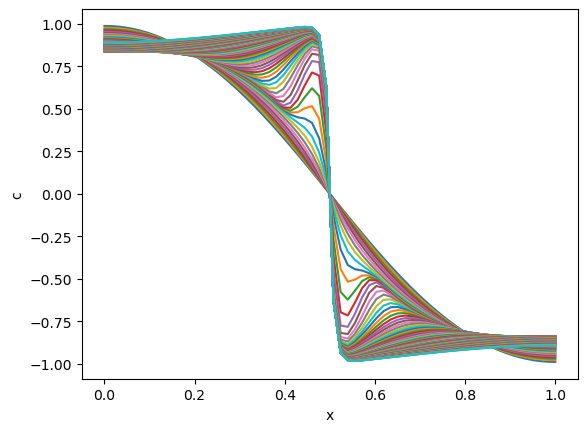

In [10]:
phi_p = lambda x, y: y**2*x-y
phi_pp = lambda x, y: y**2
solver = SemiImplicitCH(0, 1, N, lambda x: np.cos(np.pi * x), phi, phi_p, phi_pp)
vals = []
for i in range(n_steps):
    solver.step()
    if i % int(sample_every) == 0:
        vals.append(solver.Un[:N])

plt.plot(solver.mesh, list(zip(*vals)))
plt.ylabel('c')
plt.xlabel('x')

In [ ]:
eps = 0.01
a = 0
b = 1
N = 100
dx = (b-a)/N
mesh = np.linspace(a, b, N)

ic = lambda x: np.cos(np.pi * x)
phi_p = lambda x: -x+x**3
phi_pp = lambda x: -1 + 3*x**2

A = np.diag(np.repeat(-2, N)) + np.diag(np.repeat(1, N-1), 1) + np.diag(np.repeat(1, N-1), -1)
A[0][1] *= 2
A[-1][-2] *= 2

C0 = ic(mesh)
W0 = phi_p(C0)/eps - eps * A@C0/(dx**2)

dt = dx**4*2

mu = dt / (dx**2)

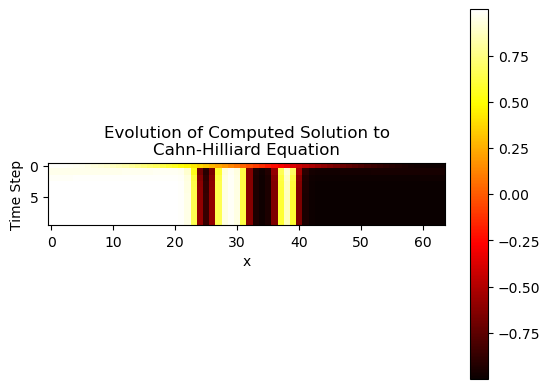

In [47]:
plt.imshow(np.array(vals), cmap='hot', interpolation='nearest')
# plt.xticks([0, 25, 50, 75, 99], [0, 0.25, 0.5, 0.75, 1])
# plt.clim([-1, 1])
plt.colorbar()
plt.ylabel('Time Step')
plt.xlabel('x')
plt.title('Evolution of Computed Solution to\nCahn-Hilliard Equation')
plt.show()